# Notebook 5 — Visualisasi Spasial Terpadu, Peta per Kejadian (Per-Event Maps), dan Sintesis Oseanografi

**Proyek:** Analisis Spatiotemporal Marine Heatwaves (MHW), Klorofil-a, dan Konteks Perikanan Tangkap Provinsi Nusa Tenggara Timur  
**Dokumen Rujukan Metodologis:** `REVISI_PBL.md` (Bagian 8.1 & 8.2)

---

## 1. Tujuan dan Standar Visualisasi

1. **Sintesis Komposit 2000–2020:** Menggambarkan variabilitas SST, anomali termal, dan respons klorofil-a lintas dekade di NTT.
2. **Peta Spasial per Kejadian (Per-Event Maps — Mandat Utama PRD):**
   - Menghasilkan visualisasi resolusi tinggi untuk 3 kejadian MHW paling masif di perairan NTT:
     - **Peta A (Luas Sebaran):** Sel-sel perairan yang teridentifikasi mengalami kondisi MHW selama kejadian.
     - **Peta B (Intensitas Maksimum):** Suhu anomali puncak ($^\circ\text{C}$ di atas klimatologi) pada masing-masing sel grid.
     - **Peta C (Durasi Lokal):** Jumlah hari aktif MHW pada masing-masing sel grid selama kejadian berlangsung.
3. **Penyelarasan Kartografi:** Menggunakan skala warna perceptually-uniform, rasio aspek geografis presisi, dan garis kontur pulau-pulau utama NTT.


---
## 1. Konfigurasi dan Pengaturan Gaya Visual

In [1]:
import sys
import os
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

# Tambahkan path folder config dan scripts revisi
notebook_dir = Path(os.path.abspath('')).resolve()
current = notebook_dir
while current != current.parent:
    if (current / 'config' / 'project_config.py').exists():
        project_root = current
        break
    current = current.parent
else:
    project_root = Path(r"G:\My Drive\KLIMTROP\PBL")


if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
if str(project_root / 'config') not in sys.path:
    sys.path.insert(0, str(project_root / 'config'))

if 'project_config' in sys.modules:
    del sys.modules['project_config']

import project_config as cfg

# Pengaturan Global Matplotlib untuk Kualitas Publikasi
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = cfg.FIGURE_DPI

print("Pengaturan visualisasi standar publikasi siap.")

Pengaturan visualisasi standar publikasi siap.


### Utilitas Visualisasi (Inline)

In [2]:
# ================================================================
# UTILITAS VISUALISASI (di-inline dari visualization_utils.py)
# ================================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.colors import LogNorm, Normalize, BoundaryNorm
from scipy.ndimage import map_coordinates, gaussian_filter
from pathlib import Path

try:
    import geopandas as gpd
    HAS_GEOPANDAS = True
except ImportError:
    HAS_GEOPANDAS = False

# Path GeoJSON batas daratan pulau NTT
_vz_root = globals().get('project_root') or globals().get('PROJECT_ROOT') or (getattr(cfg, 'PROJECT_ROOT', None) if 'cfg' in globals() else None)
if _vz_root is None:
    _vz_root = Path('.').resolve()
COASTLINE_GEOJSON = _vz_root / "dashboard" / "data" / "ntt_coastline.geojson"
if not COASTLINE_GEOJSON.exists():
    for _cand in [_vz_root.parent / "dashboard" / "data" / "ntt_coastline.geojson"]:
        if _cand.exists():
            COASTLINE_GEOJSON = _cand
            break

_CACHED_LAND_GDF = None

def load_ntt_coastline():
    """Memuat dan meng-cache GeoDataFrame poligon daratan kepulauan NTT."""
    global _CACHED_LAND_GDF
    if _CACHED_LAND_GDF is not None:
        return _CACHED_LAND_GDF
    if HAS_GEOPANDAS and COASTLINE_GEOJSON.exists():
        try:
            _CACHED_LAND_GDF = gpd.read_file(COASTLINE_GEOJSON)
            return _CACHED_LAND_GDF
        except Exception as e:
            print(f"Warning: Gagal memuat ntt_coastline.geojson: {e}")
            return None
    return None

def add_land_mask(ax, gdf_land=None, facecolor="#e4e4e4", edgecolor="#3a3a3a", linewidth=0.6, zorder=5):
    """Menambahkan poligon pulau-pulau NTT ke axis Matplotlib."""
    if gdf_land is None:
        gdf_land = load_ntt_coastline()
    if gdf_land is not None:
        gdf_land.plot(ax=ax, facecolor=facecolor, edgecolor=edgecolor, linewidth=linewidth, zorder=zorder)

def setup_spatial_axis(ax, lon_extent=None, lat_extent=None, title=None, fontsize_title=11, xlabel="Bujur (°BT)", ylabel="Lintang (°LS)"):
    """Format sumbu kartografi standar dengan label koordinat presisi dan grid tipis."""
    if lon_extent is not None:
        ax.set_xlim(lon_extent)
    if lat_extent is not None:
        ax.set_ylim(lat_extent)
    ax.set_aspect("equal")
    ax.grid(True, linestyle=":", alpha=0.35, color="gray", zorder=1)
    if title:
        ax.set_title(title, fontsize=fontsize_title, fontweight="bold", pad=7)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=9.5)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=9.5)
    ax.tick_params(axis="both", labelsize=8.5)

def refine_field(lon, lat, data, factor="auto", sigma_frac=0.45, min_weight=0.5, target_step=0.05):
    """
    Memperhalus medan 2D beresolusi kasar agar kontur tidak kotak-kotak.
    Metode: interpolasi bilinear + gaussian dengan pembobotan sadar-NaN.
    """
    lon = np.asarray(lon, dtype=float)
    lat = np.asarray(lat, dtype=float)
    arr = np.asarray(data, dtype=float)
    if factor == "auto":
        step = max(float(np.nanmedian(np.abs(np.diff(lon)))) if lon.size > 1 else target_step, 1e-9)
        factor = int(min(8, max(1, round(step / target_step))))
    factor = int(factor)
    if factor <= 1 or arr.ndim != 2 or arr.shape[0] < 2 or arr.shape[1] < 2:
        return lon, lat, arr
    ny, nx = arr.shape
    valid = np.isfinite(arr)
    filled = np.where(valid, arr, 0.0)
    yy = np.linspace(0, ny - 1, (ny - 1) * factor + 1)
    xx = np.linspace(0, nx - 1, (nx - 1) * factor + 1)
    gy, gx = np.meshgrid(yy, xx, indexing="ij")
    num = map_coordinates(filled, [gy, gx], order=1, mode="nearest")
    den = map_coordinates(valid.astype(float), [gy, gx], order=1, mode="nearest")
    sigma = sigma_frac * factor
    if sigma > 0:
        num = gaussian_filter(num, sigma, mode="nearest")
        den = gaussian_filter(den, sigma, mode="nearest")
    with np.errstate(all="ignore"):
        out = np.where(den >= min_weight, num / den, np.nan)
    lon_f = np.interp(xx, np.arange(nx), lon)
    lat_f = np.interp(yy, np.arange(ny), lat)
    return lon_f, lat_f, out

def plot_smooth_map(ax, lon, lat, data, var_type="continuous", cmap="coolwarm",
                    vmin=None, vmax=None, norm=None, levels=35, title=None,
                    cbar=True, cbar_label="", cbar_shrink=0.8, cbar_fraction=0.046,
                    cbar_pad=0.04, extend="both", gdf_land=None,
                    land_color="#e4e4e4", land_edge="#3a3a3a", refine="auto"):
    """Merender peta spasial berkualitas tinggi dengan overlay garis pantai NTT."""
    if gdf_land is None:
        gdf_land = load_ntt_coastline()
    lon_min, lon_max = float(np.nanmin(lon)), float(np.nanmax(lon))
    lat_min, lat_max = float(np.nanmin(lat)), float(np.nanmax(lat))
    if refine:
        lon, lat, data = refine_field(lon, lat, data, factor=refine)
    if var_type == "continuous":
        if vmin is None: vmin = float(np.nanmin(data))
        if vmax is None: vmax = float(np.nanmax(data))
        contour_levels = np.linspace(vmin, vmax, levels)
        cs = ax.contourf(lon, lat, data, levels=contour_levels, cmap=cmap, vmin=vmin, vmax=vmax, extend=extend, zorder=2)
    elif var_type == "log":
        if norm is None:
            norm = LogNorm(vmin=vmin if vmin is not None else 0.05, vmax=vmax if vmax is not None else 2.5)
        log_levels = np.geomspace(norm.vmin, norm.vmax, levels)
        cs = ax.contourf(lon, lat, data, levels=log_levels, cmap=cmap, norm=norm, extend=extend, zorder=2)
    elif var_type == "discrete":
        d_min = int(np.floor(np.nanmin(data))) if vmin is None else int(vmin)
        d_max = int(np.ceil(np.nanmax(data))) if vmax is None else int(vmax)
        discrete_levels = np.arange(d_min - 0.5, d_max + 1.5, 1.0)
        norm_disc = BoundaryNorm(discrete_levels, ncolors=256)
        cs = ax.contourf(lon, lat, data, levels=discrete_levels, cmap=cmap, norm=norm_disc, zorder=2)
    elif var_type == "binary":
        cs = ax.contourf(lon, lat, data, levels=[-0.5, 0.5, 1.5], cmap=cmap, vmin=0, vmax=1, zorder=2)
    else:
        cs = ax.pcolormesh(lon, lat, data, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto", zorder=2)
    add_land_mask(ax, gdf_land=gdf_land, facecolor=land_color, edgecolor=land_edge, linewidth=0.6, zorder=5)
    setup_spatial_axis(ax, (lon_min, lon_max), (lat_min, lat_max), title=title)
    cb = None
    if cbar:
        cb = plt.colorbar(cs, ax=ax, shrink=cbar_shrink, fraction=cbar_fraction, pad=cbar_pad)
        if cbar_label:
            cb.set_label(cbar_label, fontsize=9)
        cb.ax.tick_params(labelsize=8)
        if var_type == "continuous":
            cb.locator = ticker.MaxNLocator(nbins=6)
            cb.update_ticks()
    return cs, cb

print("✅ Utilitas visualisasi siap.")

✅ Utilitas visualisasi siap.


---
## 2. Pemuatan Seluruh Dataset Hasil Analisis Terverifikasi

In [3]:
# Pemuatan data terpadu
print("Memuat dataset untuk visualisasi dan sintesis spasial...")
ds_sst = xr.open_dataset(cfg.SST_MERGED_OUTPUT)
ds_chla = xr.open_dataset(cfg.CHLA_MERGED_OUTPUT)
ds_spatial_mhw = xr.open_dataset(cfg.SST_CLIMATOLOGY_OUTPUT)
ds_combined = xr.open_dataset(cfg.COMBINED_OUTPUT)

df_events = pd.read_csv(cfg.MHW_EVENTS_OUTPUT)
df_annual_mhw_1d = pd.read_csv(cfg.MHW_METRICS_OUTPUT)          # referensi (rata-rata SST regional 1D)
# REVISI (per grid): metrik tahunan dari katalog regional spasial (Notebook 2, bagian 7.2); fallback ke 1D bila belum ada
_annual_spatial = cfg.PROCESSED_DIR / "mhw_annual_metrics_spatial_ntt.csv"
df_annual_mhw = pd.read_csv(_annual_spatial) if _annual_spatial.exists() else df_annual_mhw_1d
for _need in ["mhw_mask_daily_ntt.nc", "mhw_event_maps_ntt.nc", "sst_daymean_21yr_ntt.nc"]:
    if not (cfg.PROCESSED_DIR / _need).exists():
        raise FileNotFoundError(f"{_need} tidak ditemukan di {cfg.PROCESSED_DIR}. Jalankan Notebook 2 (bagian 7.1-7.3) terlebih dahulu.")
ds_mask = xr.open_dataset(cfg.PROCESSED_DIR / "mhw_mask_daily_ntt.nc")
ds_event_maps = xr.open_dataset(cfg.PROCESSED_DIR / "mhw_event_maps_ntt.nc")

# Buka katalog spasial regional jika ada
catalog_file = cfg.TABLES_DIR / "mhw_events_spatial_catalog_ntt.csv"
if not catalog_file.exists():
    catalog_file = cfg.PROCESSED_DIR / "mhw_events_spatial_catalog_ntt.csv"

if catalog_file.exists():
    df_reg_events = pd.read_csv(catalog_file)
    print(f"✅ Katalog MHW Regional Spasial: {len(df_reg_events)} kejadian.")
else:
    df_reg_events = df_events

print(f"✅ Seluruh dataset berhasil dimuat ke memori.")


Memuat dataset untuk visualisasi dan sintesis spasial...


✅ Katalog MHW Regional Spasial: 33 kejadian.
✅ Seluruh dataset berhasil dimuat ke memori.


---
## 3. Figur Sintesis 1: Karakteristik Termal dan Siklus Musiman SST (2000–2020)

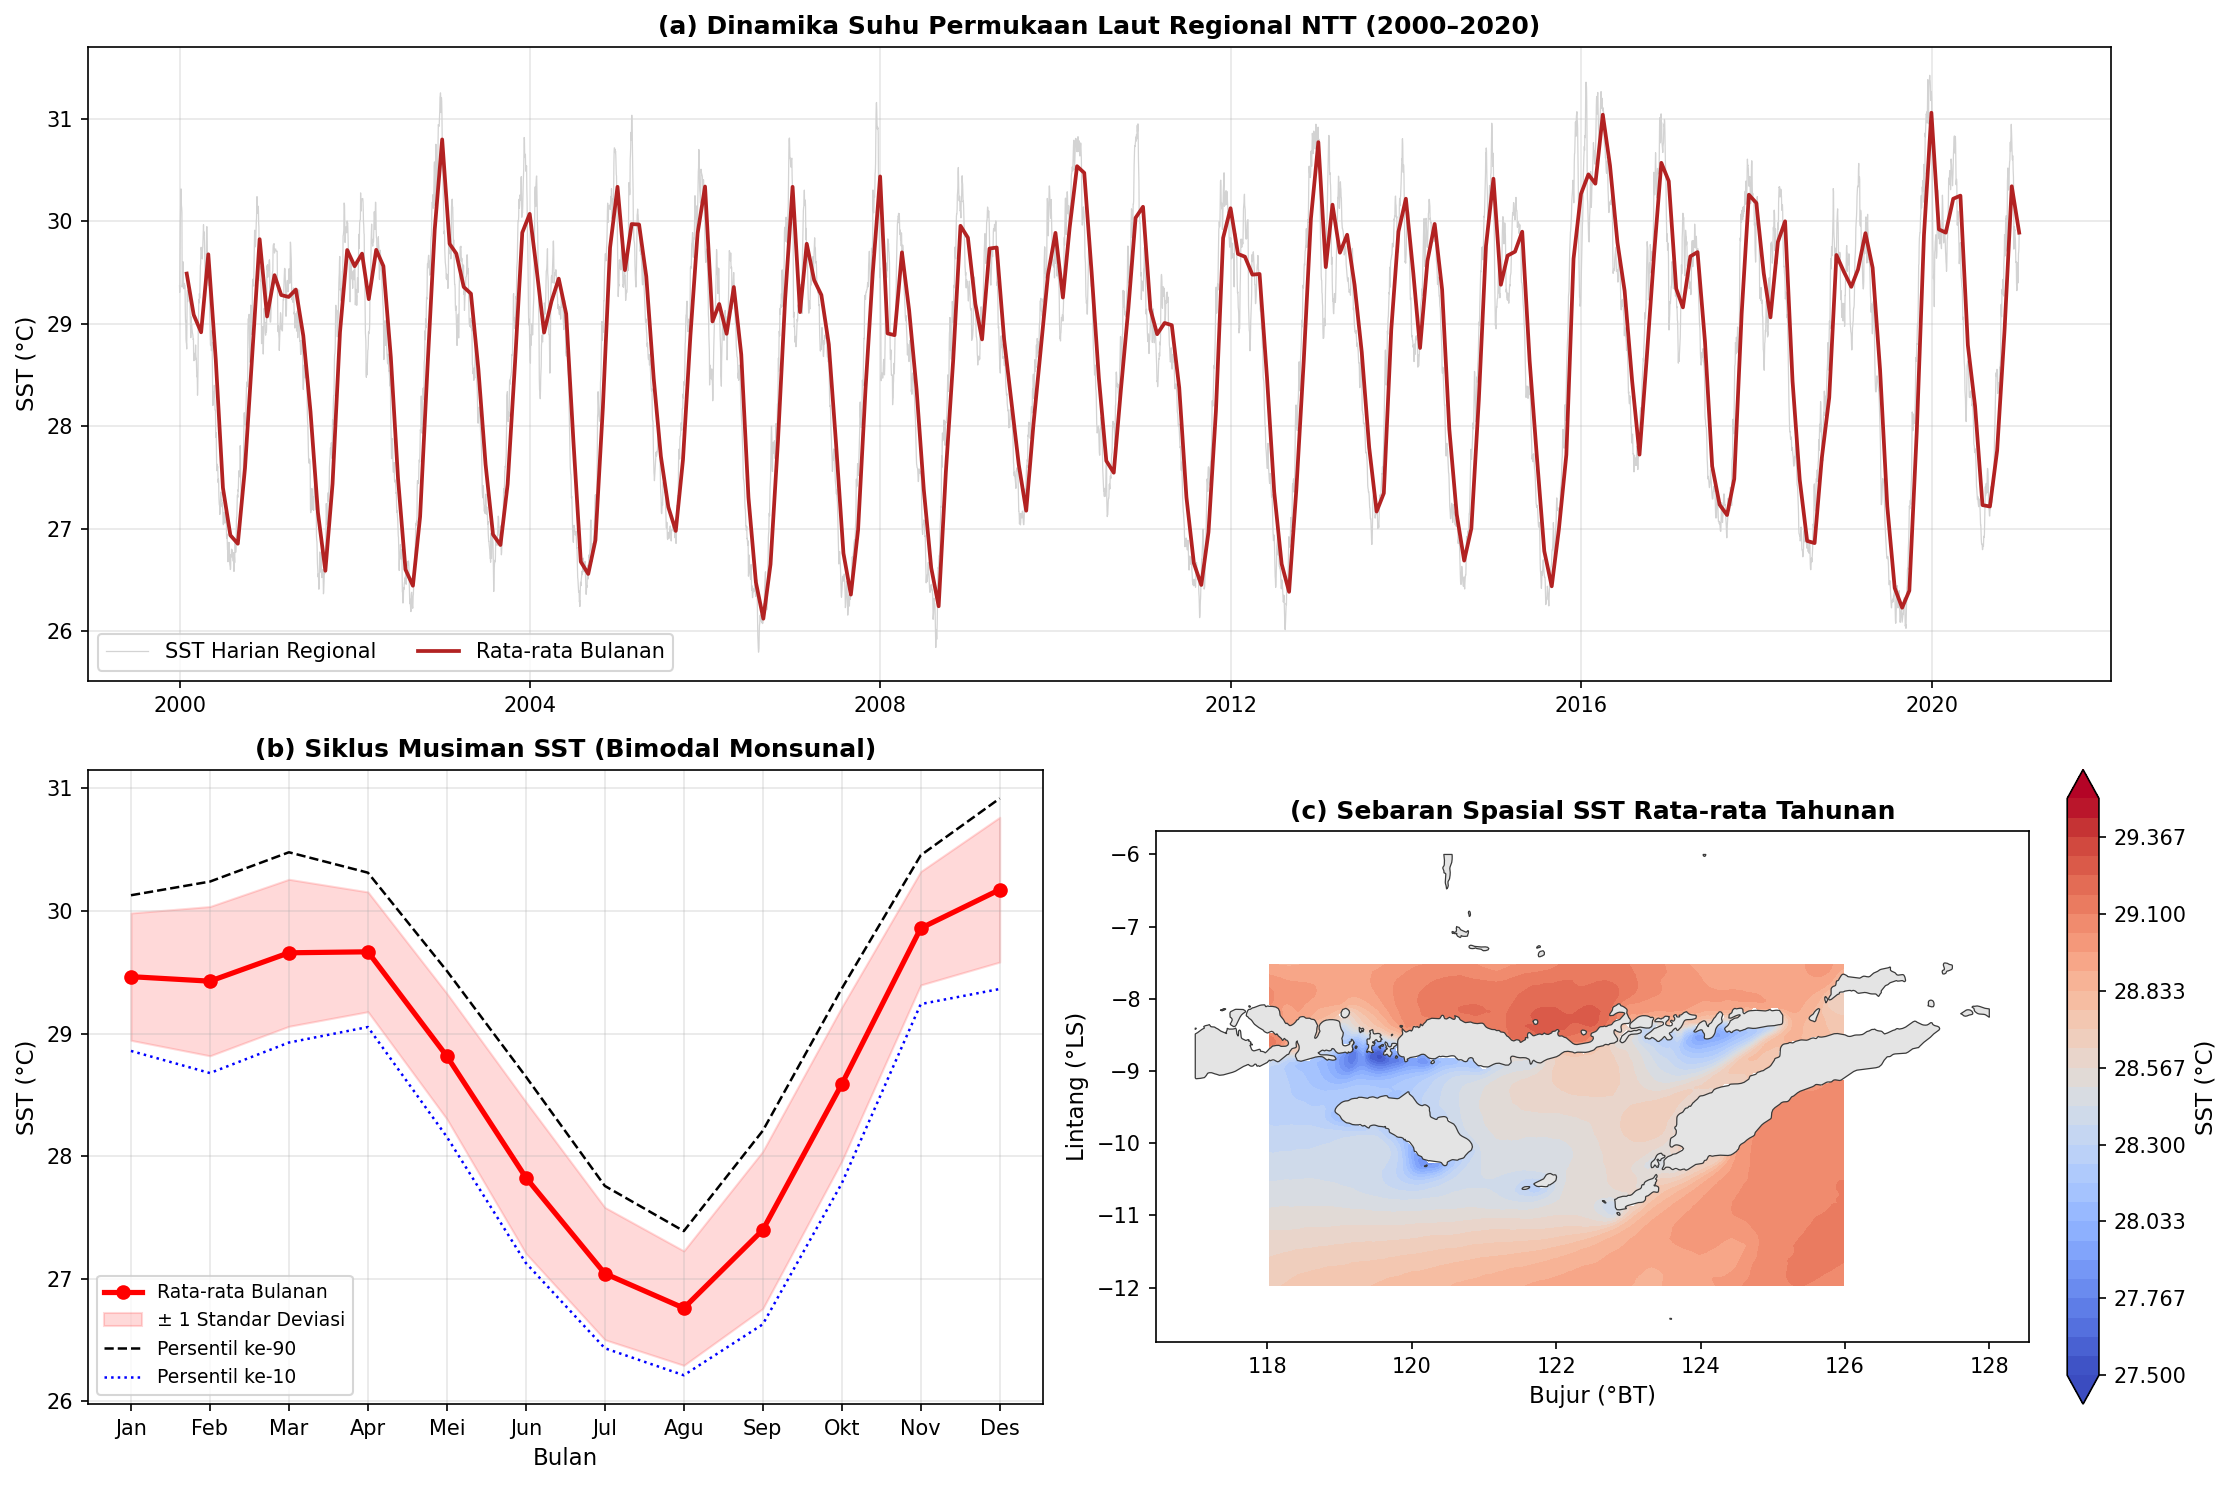

Figur 1 disimpan: G:\My Drive\KLIMTROP\PBL\outputs\figures\fig1_sintesis_karakteristik_sst.png


In [4]:
fig = plt.figure(figsize=(15, 10))
gs = gridspec.GridSpec(2, 2, height_ratios=[1, 1], figure=fig)

# Deret waktu SST harian regional
sst_mean_ts = ds_sst['sst'].mean(dim=['lat', 'lon'], skipna=True).to_series()
sst_monthly_mean = sst_mean_ts.resample('ME').mean()

# Panel (a): Deret Waktu Lengkap SST Harian & Bulanan
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(sst_mean_ts.index, sst_mean_ts.values, color='lightgrey', lw=0.6, label='SST Harian Regional')
ax1.plot(sst_monthly_mean.index, sst_monthly_mean.values, color='firebrick', lw=1.8, label='Rata-rata Bulanan')
ax1.set_ylabel('SST (°C)')
ax1.set_title('(a) Dinamika Suhu Permukaan Laut Regional NTT (2000–2020)', fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='lower left', ncol=2)

# Panel (b): Siklus Musiman Bulanan
ax2 = fig.add_subplot(gs[1, 0])
monthly_stats = sst_mean_ts.groupby(sst_mean_ts.index.month).agg(['mean', 'std', lambda x: x.quantile(0.9), lambda x: x.quantile(0.1)])
monthly_stats.columns = ['mean', 'std', 'p90', 'p10']
months = range(1, 13)
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

ax2.plot(months, monthly_stats['mean'], 'ro-', lw=2.5, label='Rata-rata Bulanan')
ax2.fill_between(months, monthly_stats['mean'] - monthly_stats['std'],
                 monthly_stats['mean'] + monthly_stats['std'], color='red', alpha=0.15, label='± 1 Standar Deviasi')
ax2.plot(months, monthly_stats['p90'], 'k--', lw=1.2, label='Persentil ke-90')
ax2.plot(months, monthly_stats['p10'], 'b:', lw=1.2, label='Persentil ke-10')
ax2.set_xticks(months)
ax2.set_xticklabels(month_labels)
ax2.set_xlabel('Bulan')
ax2.set_ylabel('SST (°C)')
ax2.set_title('(b) Siklus Musiman SST (Bimodal Monsunal)', fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(loc='lower left', fontsize=9)

# Panel (c): Peta SST Rata-rata Tahunan (Spasial)
ax3 = fig.add_subplot(gs[1, 1])
sst_annual_map = ds_sst['sst'].mean(dim='time')
# REVISI: peta diperhalus (kontur) dan ditumpangi poligon daratan
lon_f, lat_f, sst_f = refine_field(ds_sst.lon.values, ds_sst.lat.values, sst_annual_map.values)
im3 = ax3.contourf(lon_f, lat_f, sst_f, levels=np.linspace(27.5, 29.5, 31), cmap=cfg.COLORMAP_SST, extend='both', zorder=2)
add_land_mask(ax3, gdf_land=load_ntt_coastline())
ax3.set_xlabel('Bujur (°BT)')
ax3.set_ylabel('Lintang (°LS)')
ax3.set_title('(c) Sebaran Spasial SST Rata-rata Tahunan', fontweight='bold')
ax3.set_aspect('equal')
cb3 = plt.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)
cb3.set_label('SST (°C)')

plt.tight_layout()
fig_path = cfg.FIGURES_DIR / "fig1_sintesis_karakteristik_sst.png"
fig.savefig(fig_path, bbox_inches='tight')
plt.show()
print(f"Figur 1 disimpan: {fig_path}")

---
## 4. Figur Sintesis 2: Garis Waktu dan Evolusi Tahunan Marine Heatwave (2000–2020)

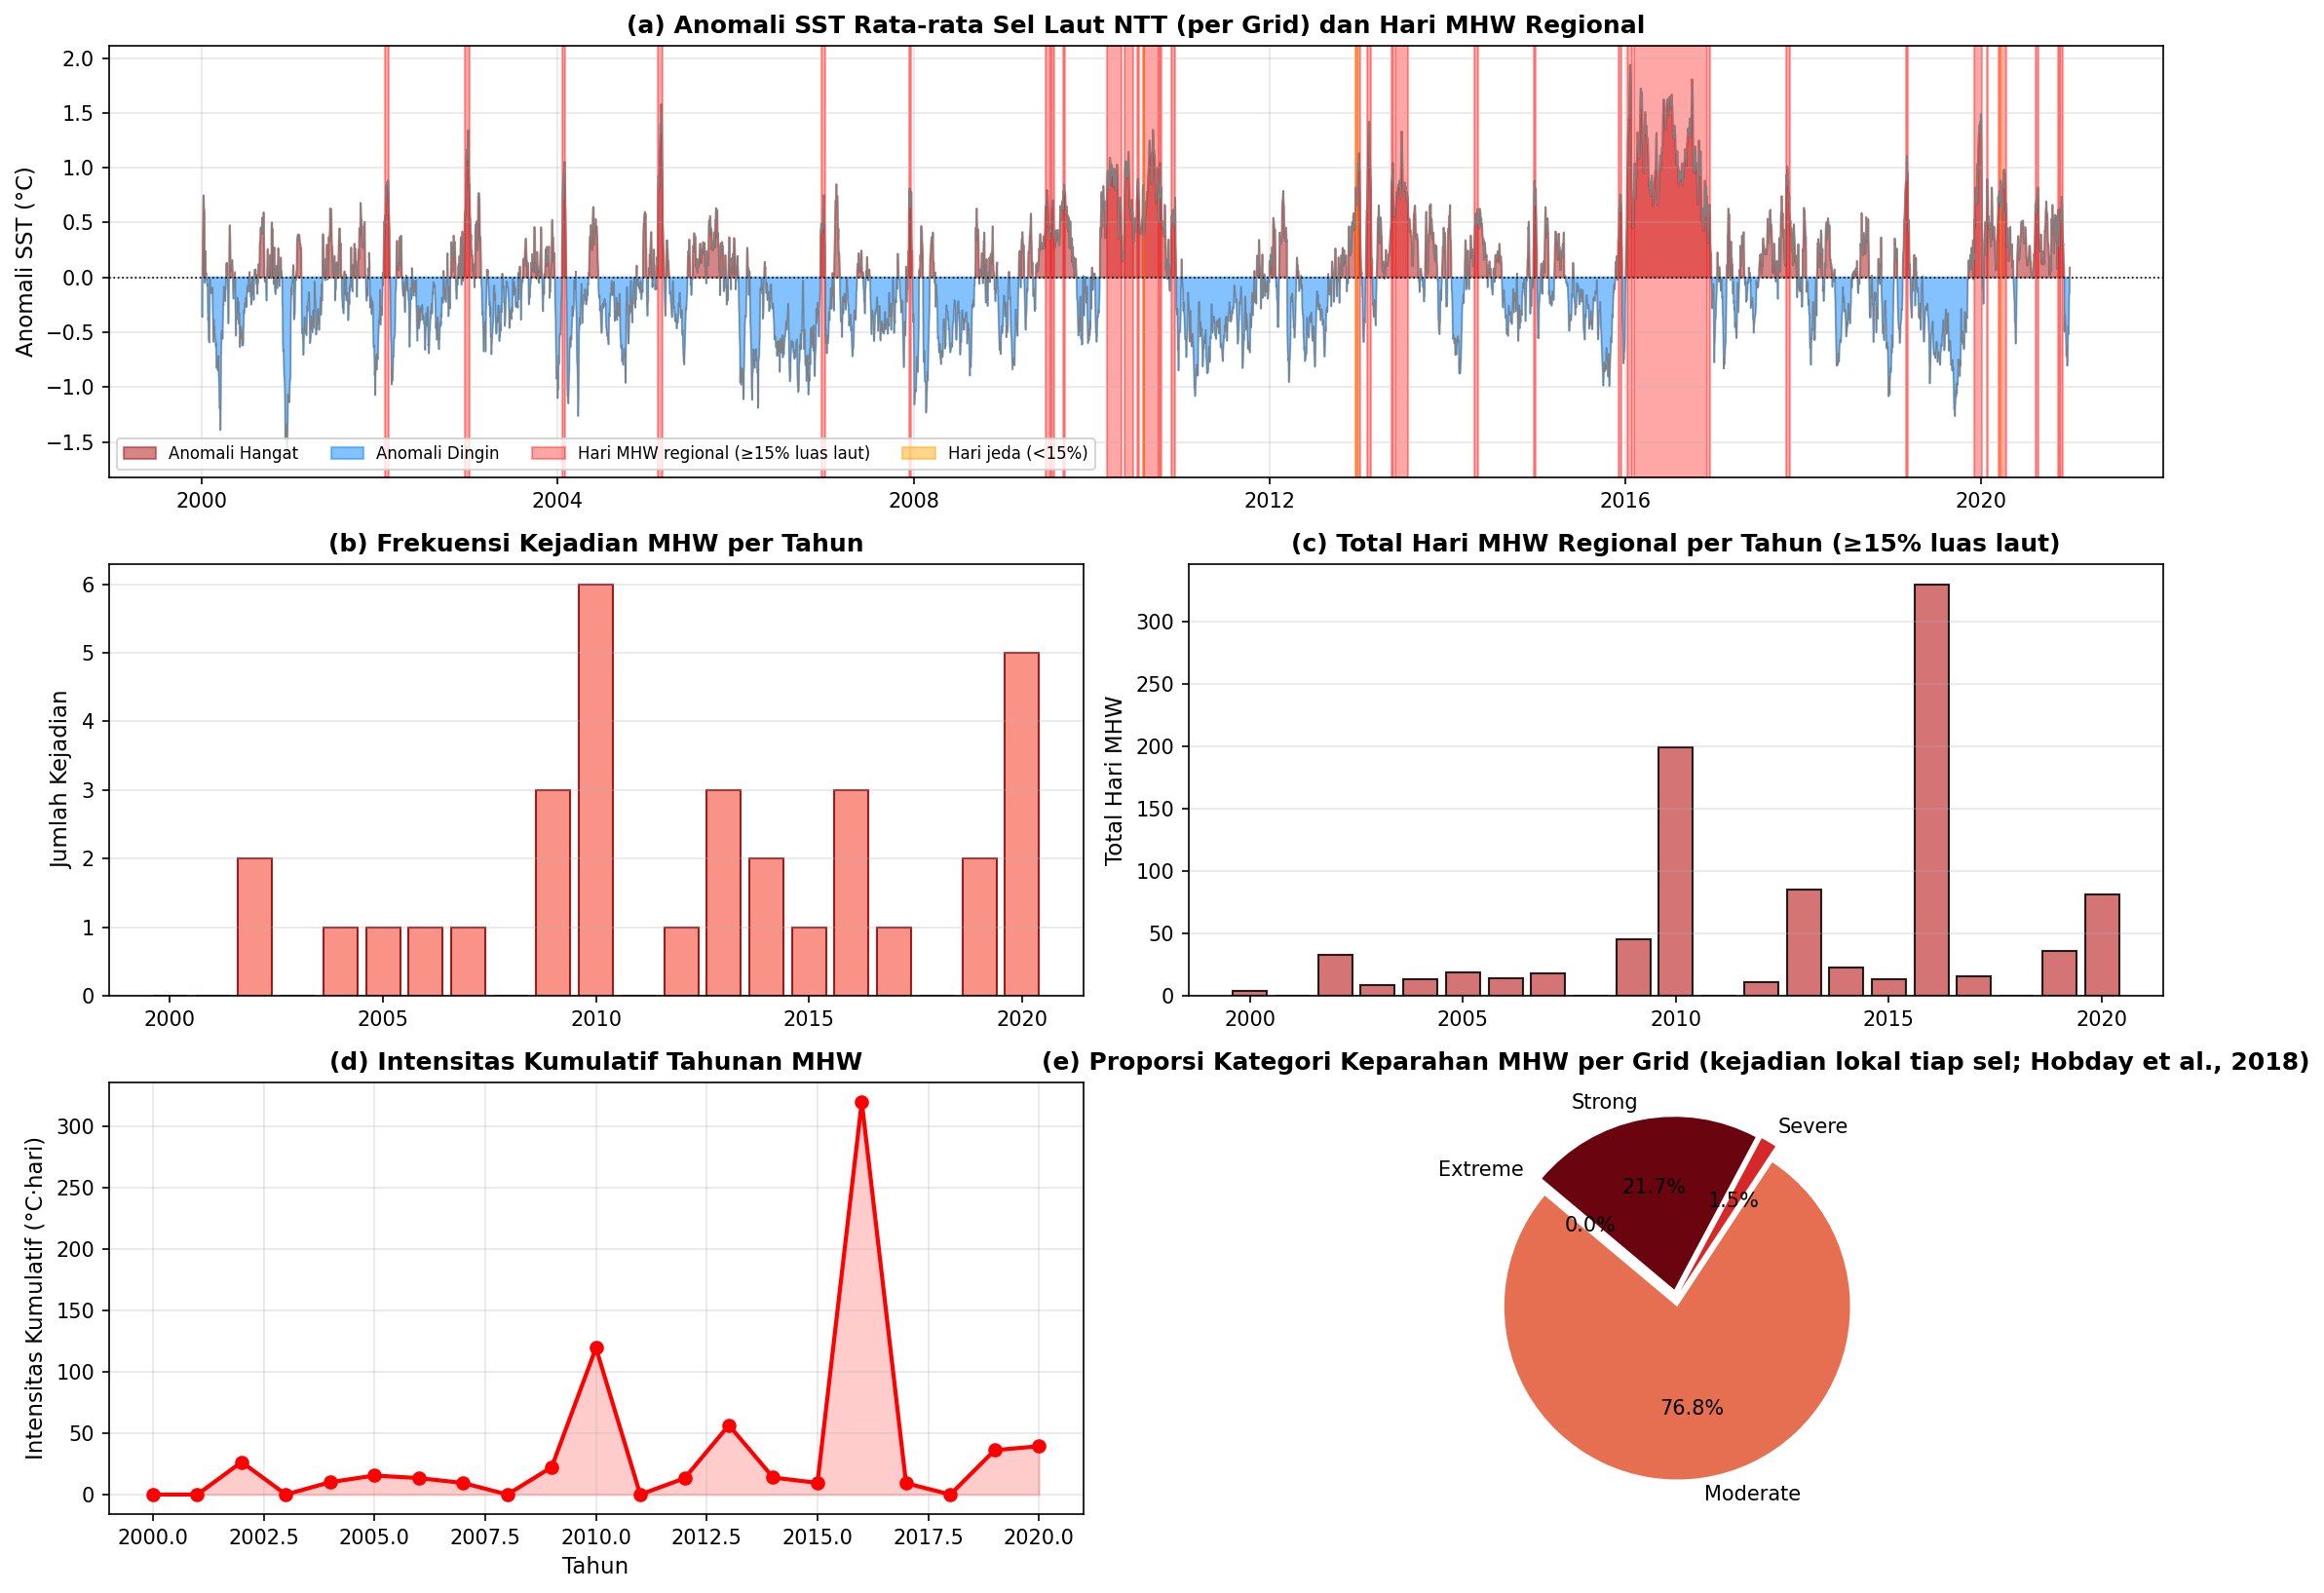

Figur 2 disimpan: G:\My Drive\KLIMTROP\PBL\outputs\figures\fig2_sintesis_timeline_mhw.png


In [5]:
fig = plt.figure(figsize=(15, 11))
gs = gridspec.GridSpec(3, 2, figure=fig)

# Panel (a): Timeline Kejadian MHW (Frekuensi & Anomali)
ax1 = fig.add_subplot(gs[0, :])
# Ambil anomali dari sst_mean_ts
# REVISI (per grid): anomali harian = rata-rata seluruh sel laut dari (SST sel - rata-rata 21 tahun sel itu pada hari-ke-tahun yang sama)
_daymean = xr.open_dataset(cfg.PROCESSED_DIR / "sst_daymean_21yr_ntt.nc")['sst_daymean'].values
_doy = pd.DatetimeIndex(ds_sst.time.values).day_of_year.values
with np.errstate(all='ignore'):
    sst_anom = pd.Series(np.nanmean(ds_sst['sst'].values - _daymean[_doy - 1], axis=(1, 2)), index=sst_mean_ts.index)

ax1.plot(sst_anom.index, sst_anom.values, color='grey', lw=0.5)
ax1.fill_between(sst_anom.index, 0, sst_anom.values, where=(sst_anom.values > 0),
                 color='firebrick', alpha=0.55, label='Anomali Hangat')
ax1.fill_between(sst_anom.index, 0, sst_anom.values, where=(sst_anom.values <= 0),
                 color='dodgerblue', alpha=0.55, label='Anomali Dingin')

# REVISI: hanya HARI MHW REGIONAL (cakupan sel >= 15% luas laut) yang diberi warna merah; hari jeda diberi warna kuning
_ext = ds_mask['member_extent'].values
_in_ev = np.zeros(len(sst_anom), dtype=bool)
for _, ev in df_reg_events.iterrows():
    _in_ev[int(ev['start_idx']):int(ev['end_idx']) + 1] = True
ax1.fill_between(sst_anom.index, 0, 1, where=_in_ev & (_ext >= 0.15), transform=ax1.get_xaxis_transform(), color='red', alpha=0.35, label='Hari MHW regional (≥15% luas laut)')
ax1.fill_between(sst_anom.index, 0, 1, where=_in_ev & (_ext < 0.15), transform=ax1.get_xaxis_transform(), color='orange', alpha=0.45, label='Hari jeda (<15%)')

ax1.set_ylabel('Anomali SST (°C)')
ax1.set_title('(a) Anomali SST Rata-rata Sel Laut NTT (per Grid) dan Hari MHW Regional', fontweight='bold')
ax1.axhline(0, color='black', lw=0.8, ls=':')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='lower left', ncol=4, fontsize=8)

# Panel (b): Frekuensi Kejadian per Tahun
ax2 = fig.add_subplot(gs[1, 0])
ax2.bar(df_annual_mhw['tahun'], df_annual_mhw['frekuensi_kejadian'],
        color='salmon', edgecolor='darkred', alpha=0.85)
ax2.set_ylabel('Jumlah Kejadian')
ax2.set_title('(b) Frekuensi Kejadian MHW per Tahun', fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')

# Panel (c): Total Hari MHW per Tahun
ax3 = fig.add_subplot(gs[1, 1])
ax3.bar(df_annual_mhw['tahun'], df_annual_mhw['total_hari_mhw'],
        color='indianred', edgecolor='black', alpha=0.85)
ax3.set_ylabel('Total Hari MHW')
ax3.set_title('(c) Total Hari MHW Regional per Tahun (≥15% luas laut)', fontweight='bold')
ax3.grid(True, alpha=0.3, axis='y')

# Panel (d): Intensitas Kumulatif Tahunan
ax4 = fig.add_subplot(gs[2, 0])
ax4.plot(df_annual_mhw['tahun'], df_annual_mhw['intensitas_kumulatif_tahunan'], 'ro-', lw=2)
ax4.fill_between(df_annual_mhw['tahun'], 0, df_annual_mhw['intensitas_kumulatif_tahunan'], color='red', alpha=0.2)
ax4.set_xlabel('Tahun')
ax4.set_ylabel('Intensitas Kumulatif (°C·hari)')
ax4.set_title('(d) Intensitas Kumulatif Tahunan MHW', fontweight='bold')
ax4.grid(True, alpha=0.3)

# Panel (e): Proporsi Kejadian per Kategori Keparahan
ax5 = fig.add_subplot(gs[2, 1])
# REVISI (per grid): kategori keparahan dari kejadian MHW lokal tiap sel (Notebook 2)
_local_file = cfg.PROCESSED_DIR / "mhw_local_events_ntt.csv"
cat_counts = (pd.read_csv(_local_file)['category'].value_counts().sort_index() if _local_file.exists() else df_events['category'].value_counts())
colors_cat = ['#f4a261', '#e76f51', '#d62828', '#6a040f']
ax5.pie(cat_counts, labels=cat_counts.index, autopct='%1.1f%%',
        startangle=140, colors=colors_cat[:len(cat_counts)], explode=[0.05]*len(cat_counts))
ax5.set_title('(e) Proporsi Kategori Keparahan MHW per Grid (kejadian lokal tiap sel; Hobday et al., 2018)', fontweight='bold')

plt.tight_layout()
fig_path = cfg.FIGURES_DIR / "fig2_sintesis_timeline_mhw.png"
fig.savefig(fig_path, bbox_inches='tight')
plt.show()
print(f"Figur 2 disimpan: {fig_path}")

---
## 5. Figur Sintesis 3: Sebaran Spasial Multi-Parameter di Perairan NTT

✅ Gambar 3 disimpan: G:\My Drive\KLIMTROP\PBL\outputs\figures\fig3_sintesis_spasial_multiparameter.png


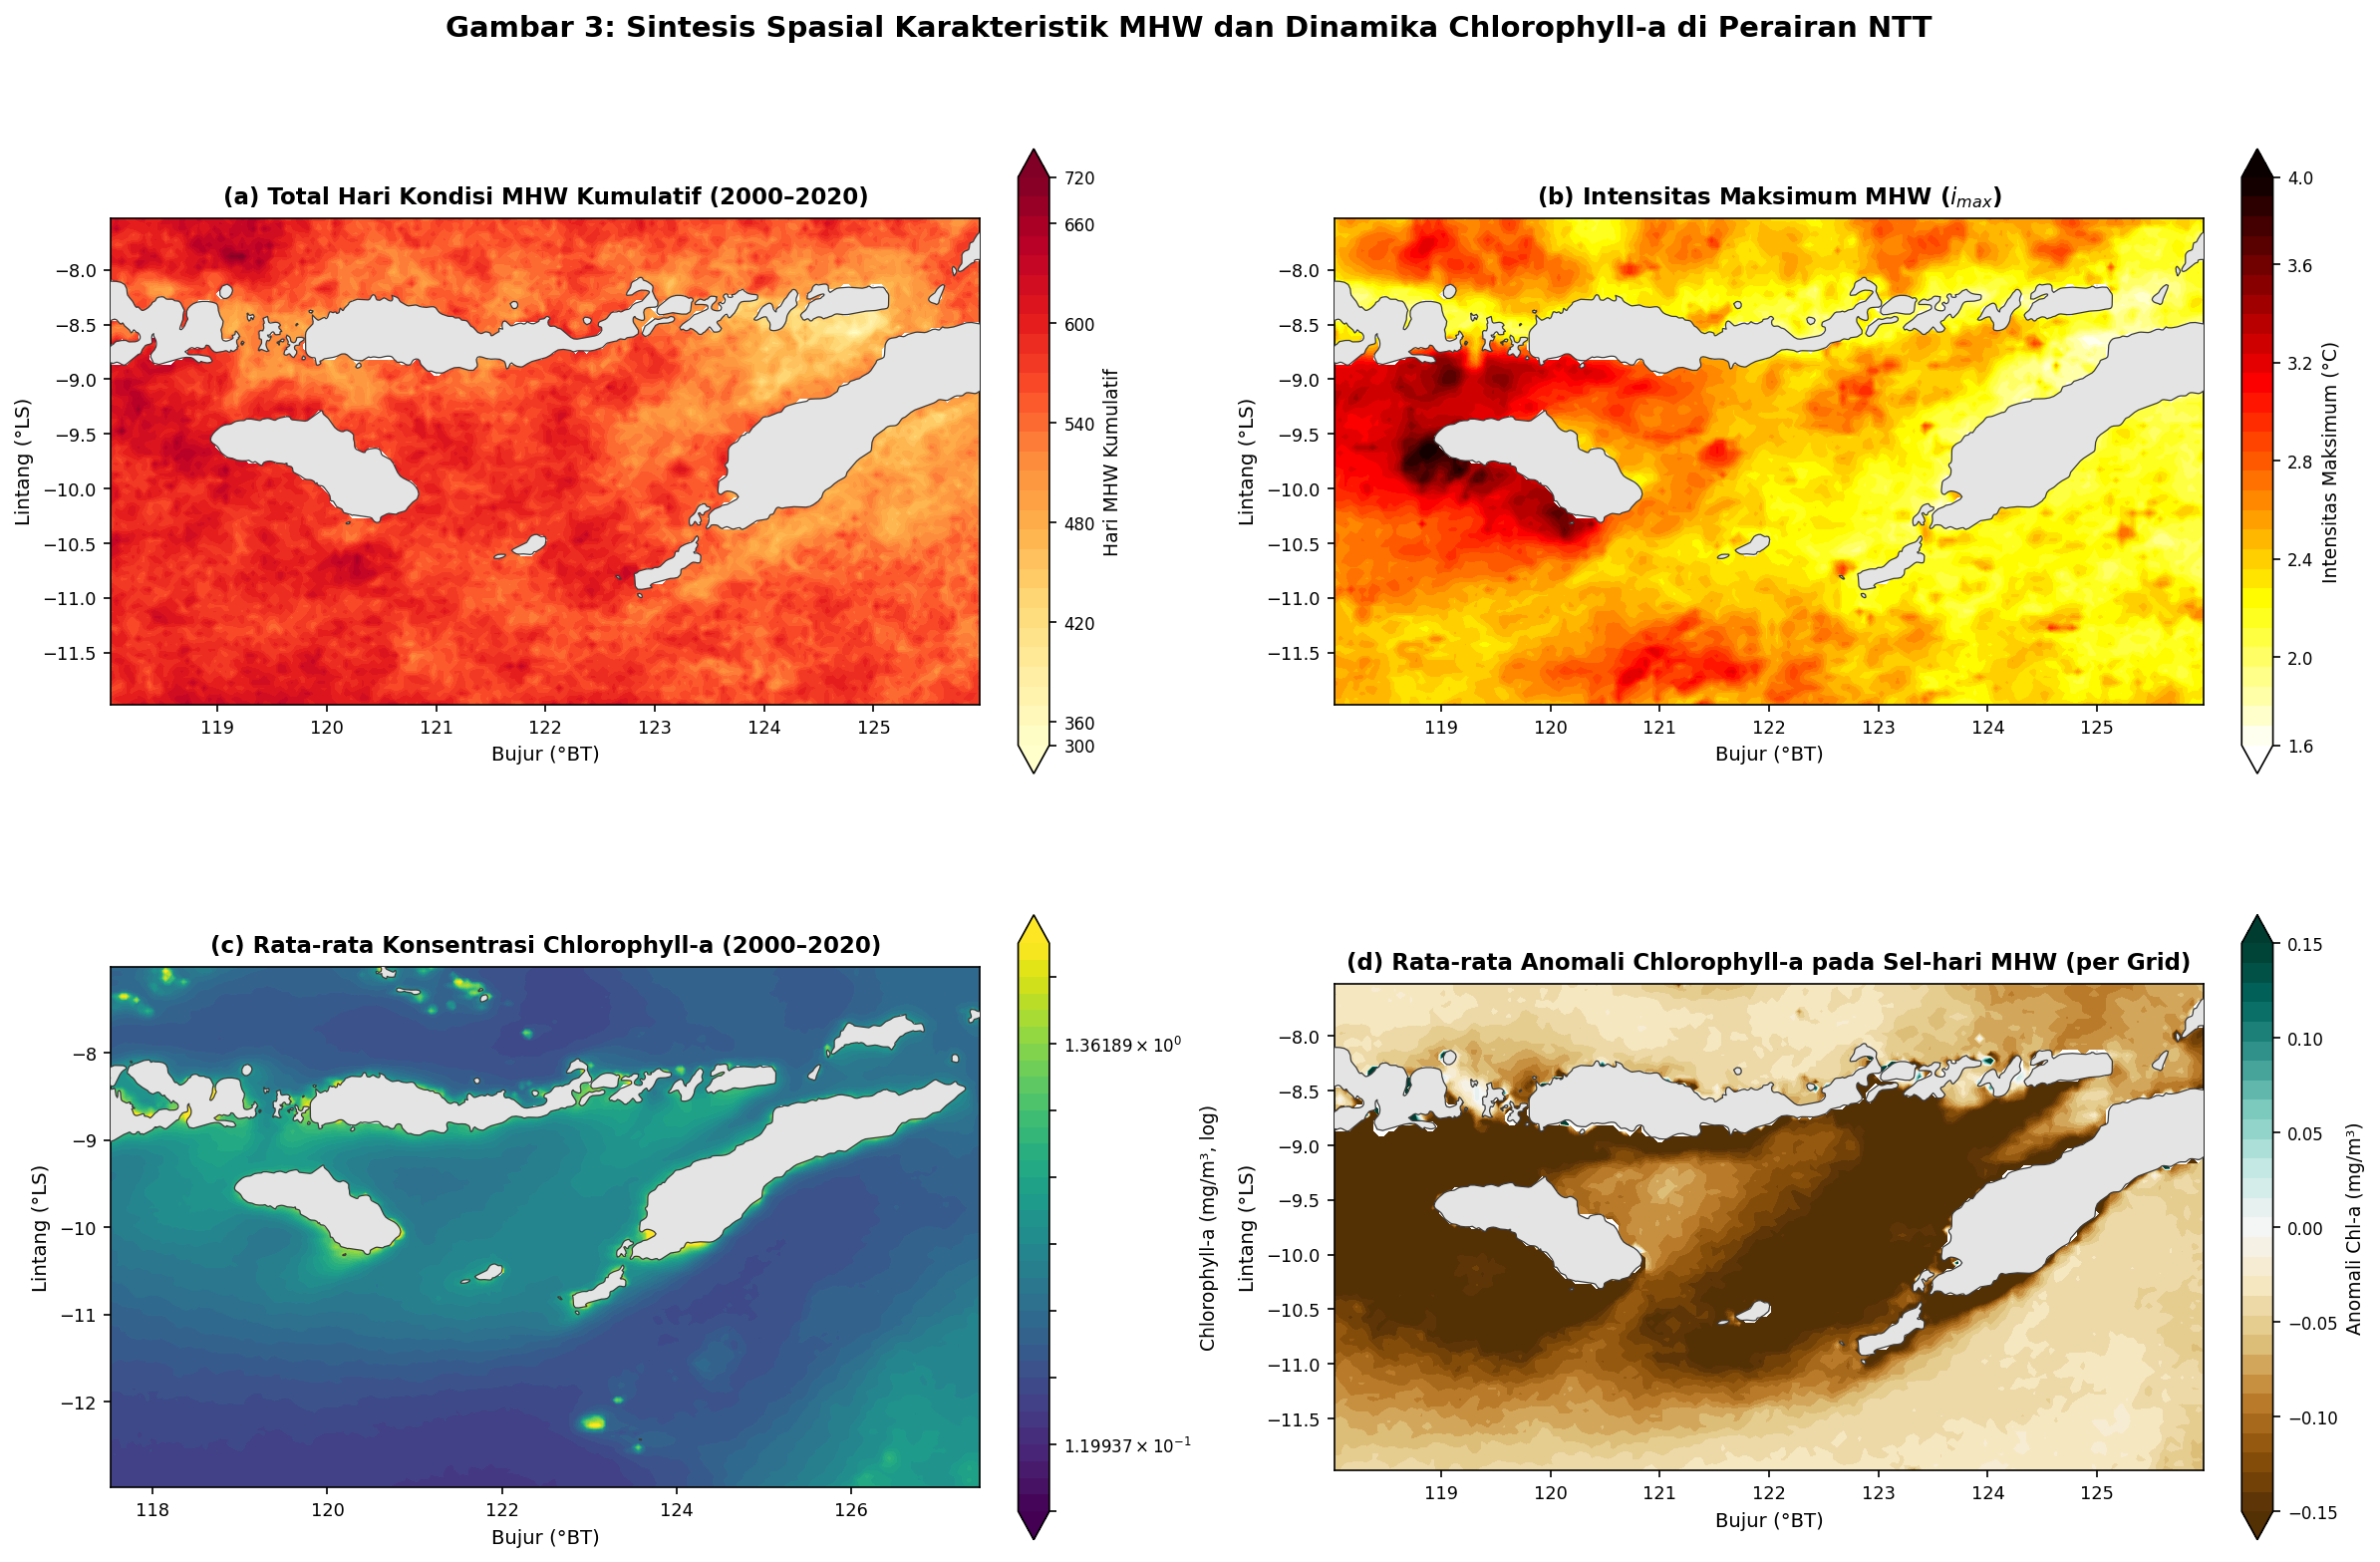

In [6]:
# Gambar 3: Sintesis Spasial Multiparameter (MHW dan Respons Klorofil-a)

gdf_land = load_ntt_coastline()
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Panel (a): Total Hari MHW Spasial Kumulatif (Kontinu)
cs1, cb1 = plot_smooth_map(
    axes[0, 0], ds_spatial_mhw.lon.values, ds_spatial_mhw.lat.values, ds_spatial_mhw['total_mhw_days'].values,
    var_type="continuous", cmap='YlOrRd', levels=30,
    title='(a) Total Hari Kondisi MHW Kumulatif (2000–2020)',
    cbar_label='Hari MHW Kumulatif', gdf_land=gdf_land
)

# Panel (b): Intensitas Maksimum MHW (Kontinu)
cs2, cb2 = plot_smooth_map(
    axes[0, 1], ds_spatial_mhw.lon.values, ds_spatial_mhw.lat.values, ds_spatial_mhw['max_intensity'].values,
    var_type="continuous", cmap='hot_r', levels=30,
    title='(b) Intensitas Maksimum MHW ($i_{max}$)',
    cbar_label='Intensitas Maksimum (°C)', gdf_land=gdf_land
)

# Panel (c): Rata-rata Spasial Chlorophyll-a (Skala Logaritmik)
chla_spatial_mean = ds_chla['chlor_a'].mean(dim='time', skipna=True).values
cs3, cb3 = plot_smooth_map(
    axes[1, 0], ds_chla.lon.values, ds_chla.lat.values, chla_spatial_mean,
    var_type="log", cmap=cfg.COLORMAP_CHLA, vmin=0.08, vmax=2.5, levels=35,
    title='(c) Rata-rata Konsentrasi Chlorophyll-a (2000–2020)',
    cbar_label='Chlorophyll-a (mg/m³, log)', gdf_land=gdf_land
)

# Panel (d): Anomali Chlorophyll-a pada sel-hari MHW (per grid, hasil Notebook 4 bagian 5.1)
_pg_file = cfg.PROCESSED_DIR / "chla_mhw_per_grid_ntt.nc"
if _pg_file.exists():
    ds_pg = xr.open_dataset(_pg_file)
    cs4, cb4 = plot_smooth_map(
        axes[1, 1], ds_pg.lon.values, ds_pg.lat.values, ds_pg['anom_mhw_ALL'].values,
        var_type="continuous", cmap='BrBG', vmin=-0.15, vmax=0.15, levels=30,
        title='(d) Rata-rata Anomali Chlorophyll-a pada Sel-hari MHW (per Grid)',
        cbar_label='Anomali Chl-a (mg/m³)', gdf_land=gdf_land
    )
else:
    axes[1, 1].text(0.5, 0.5, "Hasil per grid Notebook 4 belum tersedia", ha='center', va='center')

plt.suptitle('Gambar 3: Sintesis Spasial Karakteristik MHW dan Dinamika Chlorophyll-a di Perairan NTT',
             fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
fig_path = cfg.FIGURES_DIR / "fig3_sintesis_spasial_multiparameter.png"
fig.savefig(fig_path, bbox_inches='tight')
print(f"✅ Gambar 3 disimpan: {fig_path}")
plt.show()


---
## 6. Figur Sintesis 4: Perbandingan dan Respon Biologis Chlorophyll-a Terhadap MHW

Ringkasan Perbandingan MHW vs Non-MHW:
   Kondisi    N_Hari  Chla_Mean  Chla_Median  Chla_Std  Chla_IQR  \
0      MHW   3274395     0.2045       0.1617    0.1712    0.1069   
1  Non-MHW  38618027     0.3254       0.2312    0.3145    0.2440   

   Anomali_Mean  Anomali_Median  
0       -0.1053         -0.0578  
1       -0.0000         -0.0174  


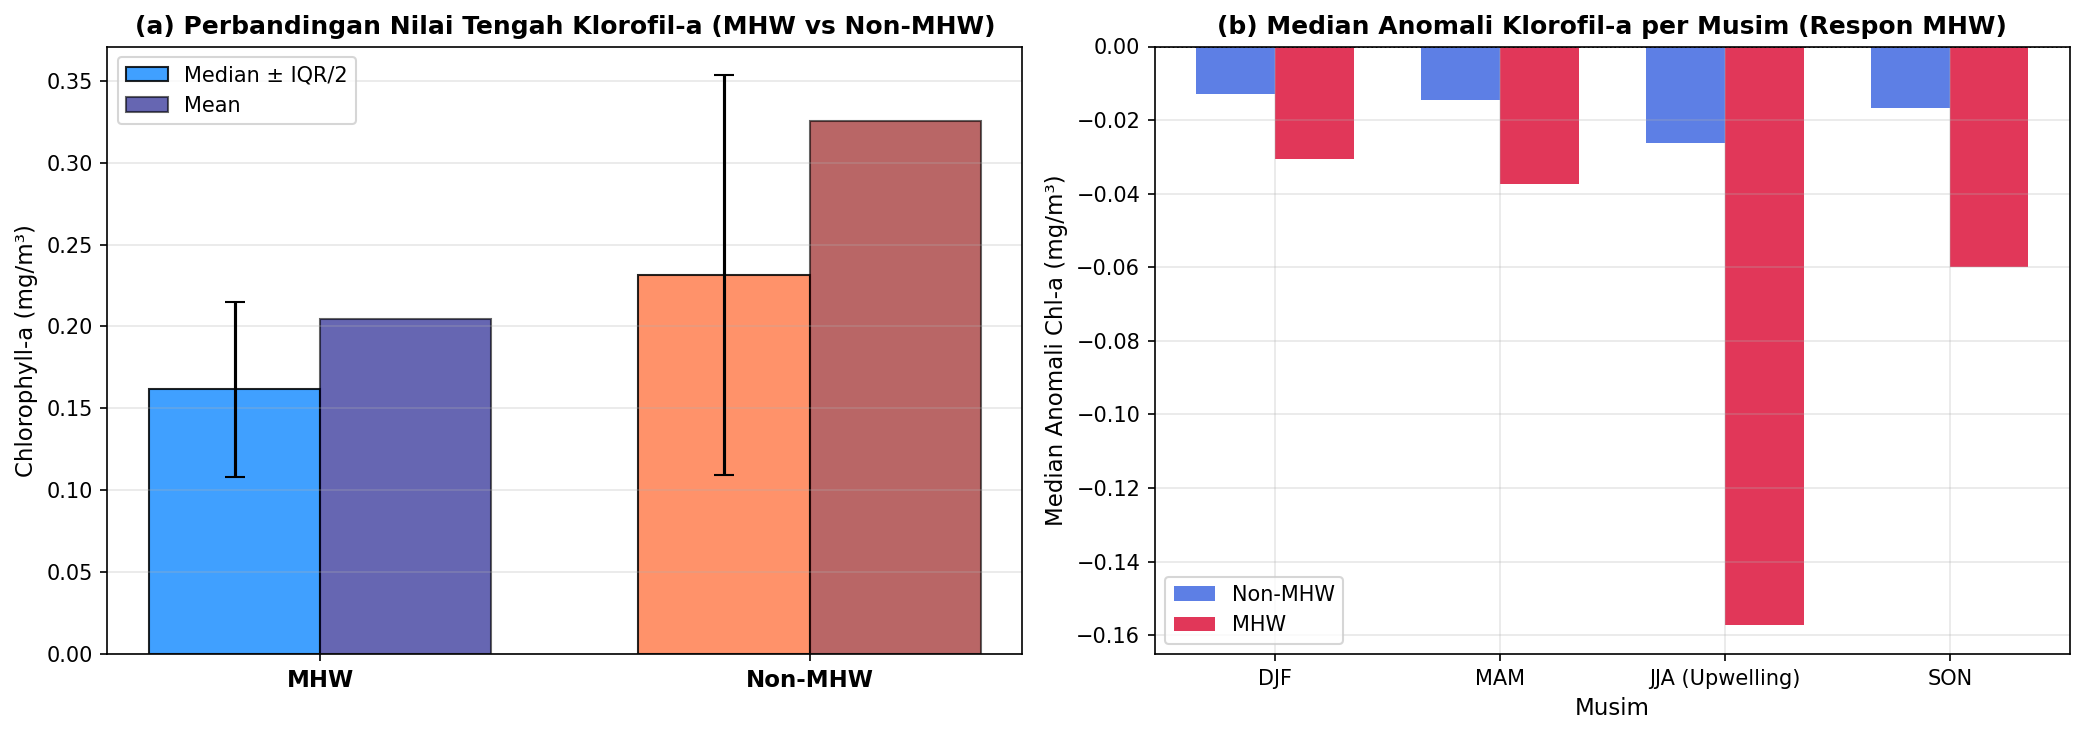

Figur 4 disimpan: G:\My Drive\KLIMTROP\PBL\outputs\figures\fig4_sintesis_respon_chla_mhw.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel (a): Boxplot Perbandingan Global
df_comp_table = pd.read_csv(cfg.COMBINED_COMPARISON_OUTPUT)
print("Ringkasan Perbandingan MHW vs Non-MHW:")
print(df_comp_table)

# Plot Komparasi Boxplot Median & IQR
categories = df_comp_table['Kondisi']
medians = df_comp_table['Chla_Median']
means = df_comp_table['Chla_Mean']
iqrs = df_comp_table['Chla_IQR']

x_pos = np.arange(len(categories))
width = 0.35

axes[0].bar(x_pos - width/2, medians, width, yerr=iqrs/2, capsize=5,
            label='Median ± IQR/2', color=['dodgerblue', 'coral'], alpha=0.85, edgecolor='black')
axes[0].bar(x_pos + width/2, means, width,
            label='Mean', color=['navy', 'darkred'], alpha=0.6, edgecolor='black')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(categories, fontsize=11, fontweight='bold')
axes[0].set_ylabel('Chlorophyll-a (mg/m³)', fontsize=11)
axes[0].set_title('(a) Perbandingan Nilai Tengah Klorofil-a (MHW vs Non-MHW)', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Panel (b): Perbandingan Anomali Berdasarkan Musim
df_seas_comp = pd.read_csv(cfg.TABLES_DIR / "chla_mhw_seasonal_comparison.csv")
season_names = ['DJF (Monsun Barat)', 'MAM (Peralihan I)', 'JJA (Monsun Timur)', 'SON (Peralihan II)']
short_seasons = ['DJF', 'MAM', 'JJA (Upwelling)', 'SON']

anom_nmhw = df_seas_comp['Anomali_Median_NonMHW']
anom_mhw = df_seas_comp['Anomali_Median_MHW']
pos_s = np.arange(len(short_seasons))

axes[1].bar(pos_s - width/2, anom_nmhw, width, label='Non-MHW', color='royalblue', alpha=0.85)
axes[1].bar(pos_s + width/2, anom_mhw, width, label='MHW', color='crimson', alpha=0.85)
axes[1].axhline(0, color='black', lw=0.8, ls=':')
axes[1].set_xticks(pos_s)
axes[1].set_xticklabels(short_seasons, fontsize=10)
axes[1].set_xlabel('Musim')
axes[1].set_ylabel('Median Anomali Chl-a (mg/m³)')
axes[1].set_title('(b) Median Anomali Klorofil-a per Musim (Respon MHW)', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig_path = cfg.FIGURES_DIR / "fig4_sintesis_respon_chla_mhw.png"
fig.savefig(fig_path, bbox_inches='tight')
plt.show()
print(f"Figur 4 disimpan: {fig_path}")

---
## 7. Tabel Sintesis Temuan Utama (Bahan Laporan)

Tabel ringkasan metrik kuantitatif terintegrasi dari seluruh komponen analisis.

---
## 5. Peta Spasial Per Kejadian (Per-Event Maps) untuk Kejadian MHW Terbesar NTT

Sesuai mandat `REVISI_PBL.md` Bagian 8.1, analisis MHW tidak hanya menyajikan satu peta rata-rata umum seluruh periode, melainkan memetakan secara detail struktur spasial dari masing-masing kejadian MHW terkuat:
- **Kolom 1 (Luas Sebaran):** Sel grid yang aktif mengalami MHW selama kejadian (persentase luasan terdampak).
- **Kolom 2 (Intensitas Maksimum):** Anomali termal puncak di atas batas klimatologi ($^\circ\text{C}$).
- **Kolom 3 (Durasi Lokal):** Jumlah hari suatu sel grid mengalami kondisi MHW selama kejadian.


Menyiapkan data spasial untuk 3 kejadian MHW regional terbesar...


✅ Peta spasial per-kejadian disimpan: G:\My Drive\KLIMTROP\PBL\outputs\figures\nb5_per_event_spatial_maps.png


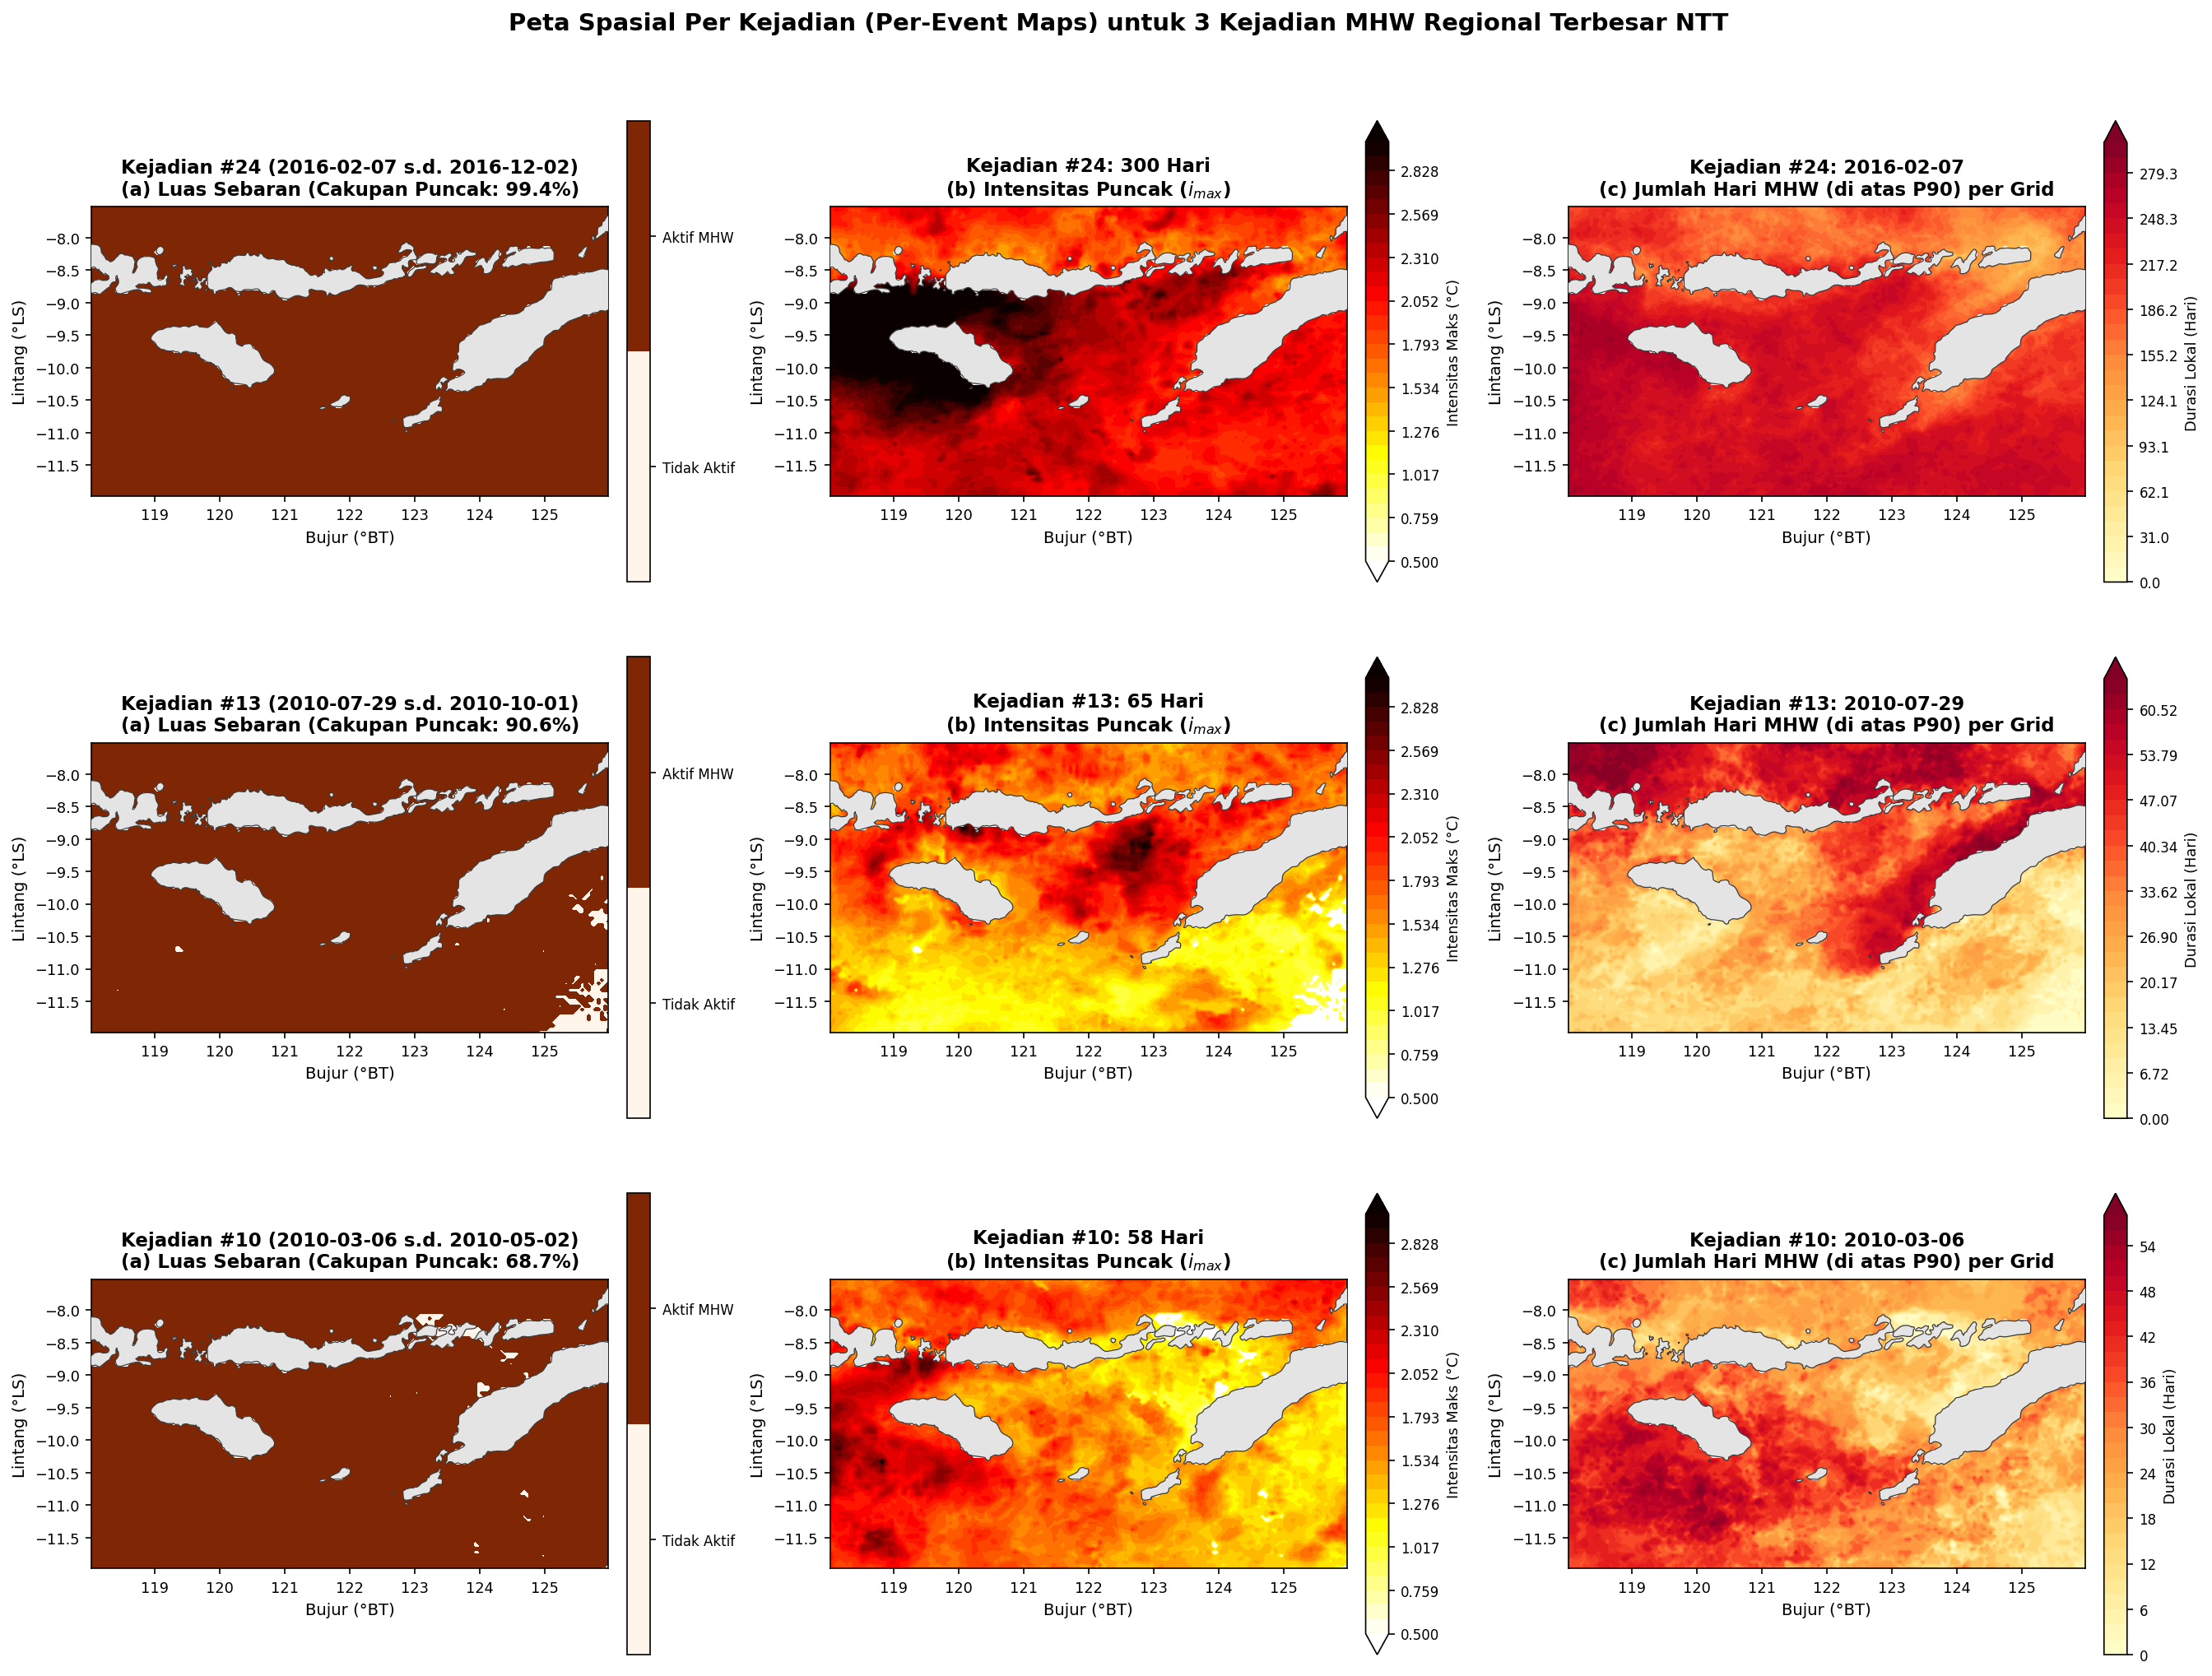

In [8]:
# Pembuatan Peta Spasial Per Kejadian (Per-Event Maps) untuk 3 Kejadian Terbesar NTT

print("Menyiapkan data spasial untuk 3 kejadian MHW regional terbesar...")
gdf_land = load_ntt_coastline()

# REVISI: gunakan mask per grid dari Notebook 2 (konsisten dan lebih cepat daripada menjalankan ulang deteksi)
is_mhw_3d = ds_mask['member'].values.astype(bool)
strict_3d = ds_mask['strict'].values.astype(bool)
intensity_3d = ds_mask['intensity'].values
df_reg = df_reg_events
ocean_mask = ds_mask['ocean_mask'].values.astype(bool)
time_dt = pd.DatetimeIndex(ds_sst.time.values)

# Pilih 3 kejadian teratas berdasarkan durasi
top3_events = df_reg.sort_values('duration_days', ascending=False).head(3).copy()

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
lon_vals = ds_sst.lon.values
lat_vals = ds_sst.lat.values

for row_idx, (_, ev) in enumerate(top3_events.iterrows()):
    s_idx = int(ev['start_idx'])
    e_idx = int(ev['end_idx'])
    ev_id = int(ev['regional_event_id'])
    s_date = str(ev['start_date'])
    e_date = str(ev['end_date'])
    dur = int(ev['duration_days'])
    pk_ext = float(ev['peak_extent_pct'])
    
    # Sub-volume kejadian
    sub_mhw = strict_3d[s_idx:e_idx+1]                                  # hari MHW sebenarnya (di atas P90), tanpa hari jeda
    sub_int = np.where(sub_mhw, intensity_3d[s_idx:e_idx+1], 0.0)
    
    # Peta A: Apakah sel pernah aktif MHW (Luas Sebaran)
    ever_active = np.any(sub_mhw, axis=0).astype(float)
    ever_active[~ocean_mask] = np.nan
    
    # Peta B: Intensitas Maksimum per grid
    max_int_ev = np.max(sub_int, axis=0)
    max_int_ev[~ocean_mask] = np.nan
    
    # Peta C: Durasi lokal per grid
    dur_local_ev = np.sum(sub_mhw, axis=0).astype(float)
    dur_local_ev[~ocean_mask] = np.nan
    
    # Plot Kolom 1: Luas Sebaran (Biner)
    lon_r, lat_r, _ = refine_field(lon_vals, lat_vals, ever_active)
    ref = lambda a: refine_field(lon_vals, lat_vals, a)[2]
    im_a = axes[row_idx, 0].contourf(lon_r, lat_r, ref(ever_active), levels=[-0.5, 0.5, 1.5],
                                    cmap='Oranges', vmin=0, vmax=1, zorder=2)
    add_land_mask(axes[row_idx, 0], gdf_land=gdf_land)
    setup_spatial_axis(axes[row_idx, 0], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                       title=f"Kejadian #{ev_id} ({s_date} s.d. {e_date})\n(a) Luas Sebaran (Cakupan Puncak: {pk_ext:.1f}%)")
    cb_a = plt.colorbar(im_a, ax=axes[row_idx, 0], ticks=[0, 1], shrink=0.8, pad=0.03)
    cb_a.ax.set_yticklabels(['Tidak Aktif', 'Aktif MHW'])
    cb_a.ax.tick_params(labelsize=8)
    
    # Plot Kolom 2: Intensitas Maksimum (Kontinu Halus)
    levels_b = np.linspace(0.5, 3.0, 30)
    im_b = axes[row_idx, 1].contourf(lon_r, lat_r, ref(max_int_ev),
                                    levels=levels_b, cmap='hot_r', extend='both', zorder=2)
    add_land_mask(axes[row_idx, 1], gdf_land=gdf_land)
    setup_spatial_axis(axes[row_idx, 1], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                       title=f"Kejadian #{ev_id}: {dur} Hari\n(b) Intensitas Puncak ($i_{{max}}$)")
    cb_b = plt.colorbar(im_b, ax=axes[row_idx, 1], shrink=0.8, pad=0.03)
    cb_b.set_label('Intensitas Maks (°C)', fontsize=8.5)
    cb_b.ax.tick_params(labelsize=8)
    
    # Plot Kolom 3: Durasi Lokal (Kontinu Halus)
    levels_c = np.linspace(0, dur, 30)
    im_c = axes[row_idx, 2].contourf(lon_r, lat_r, ref(dur_local_ev),
                                    levels=levels_c, cmap='YlOrRd', extend='max', zorder=2)
    add_land_mask(axes[row_idx, 2], gdf_land=gdf_land)
    setup_spatial_axis(axes[row_idx, 2], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                       title=f"Kejadian #{ev_id}: {s_date}\n(c) Jumlah Hari MHW (di atas P90) per Grid")
    cb_c = plt.colorbar(im_c, ax=axes[row_idx, 2], shrink=0.8, pad=0.03)
    cb_c.set_label('Durasi Lokal (Hari)', fontsize=8.5)
    cb_c.ax.tick_params(labelsize=8)

plt.suptitle('Peta Spasial Per Kejadian (Per-Event Maps) untuk 3 Kejadian MHW Regional Terbesar NTT', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
out_per_event_fig = cfg.FIGURES_DIR / "nb5_per_event_spatial_maps.png"
fig.savefig(out_per_event_fig, dpi=cfg.FIGURE_DPI, bbox_inches='tight')
print(f"✅ Peta spasial per-kejadian disimpan: {out_per_event_fig}")
plt.show()


### Peta Anomali SST dan Durasi per Grid pada 3 Kejadian Terbesar

Anomali SST per grid = rata-rata SST periode kejadian dikurangi rata-rata SST 21 tahun pada tanggal yang sama (Notebook 2, bagian 7.3). Durasi beruntun terpanjang menghitung hari berturut-turut sebagai anggota kejadian.


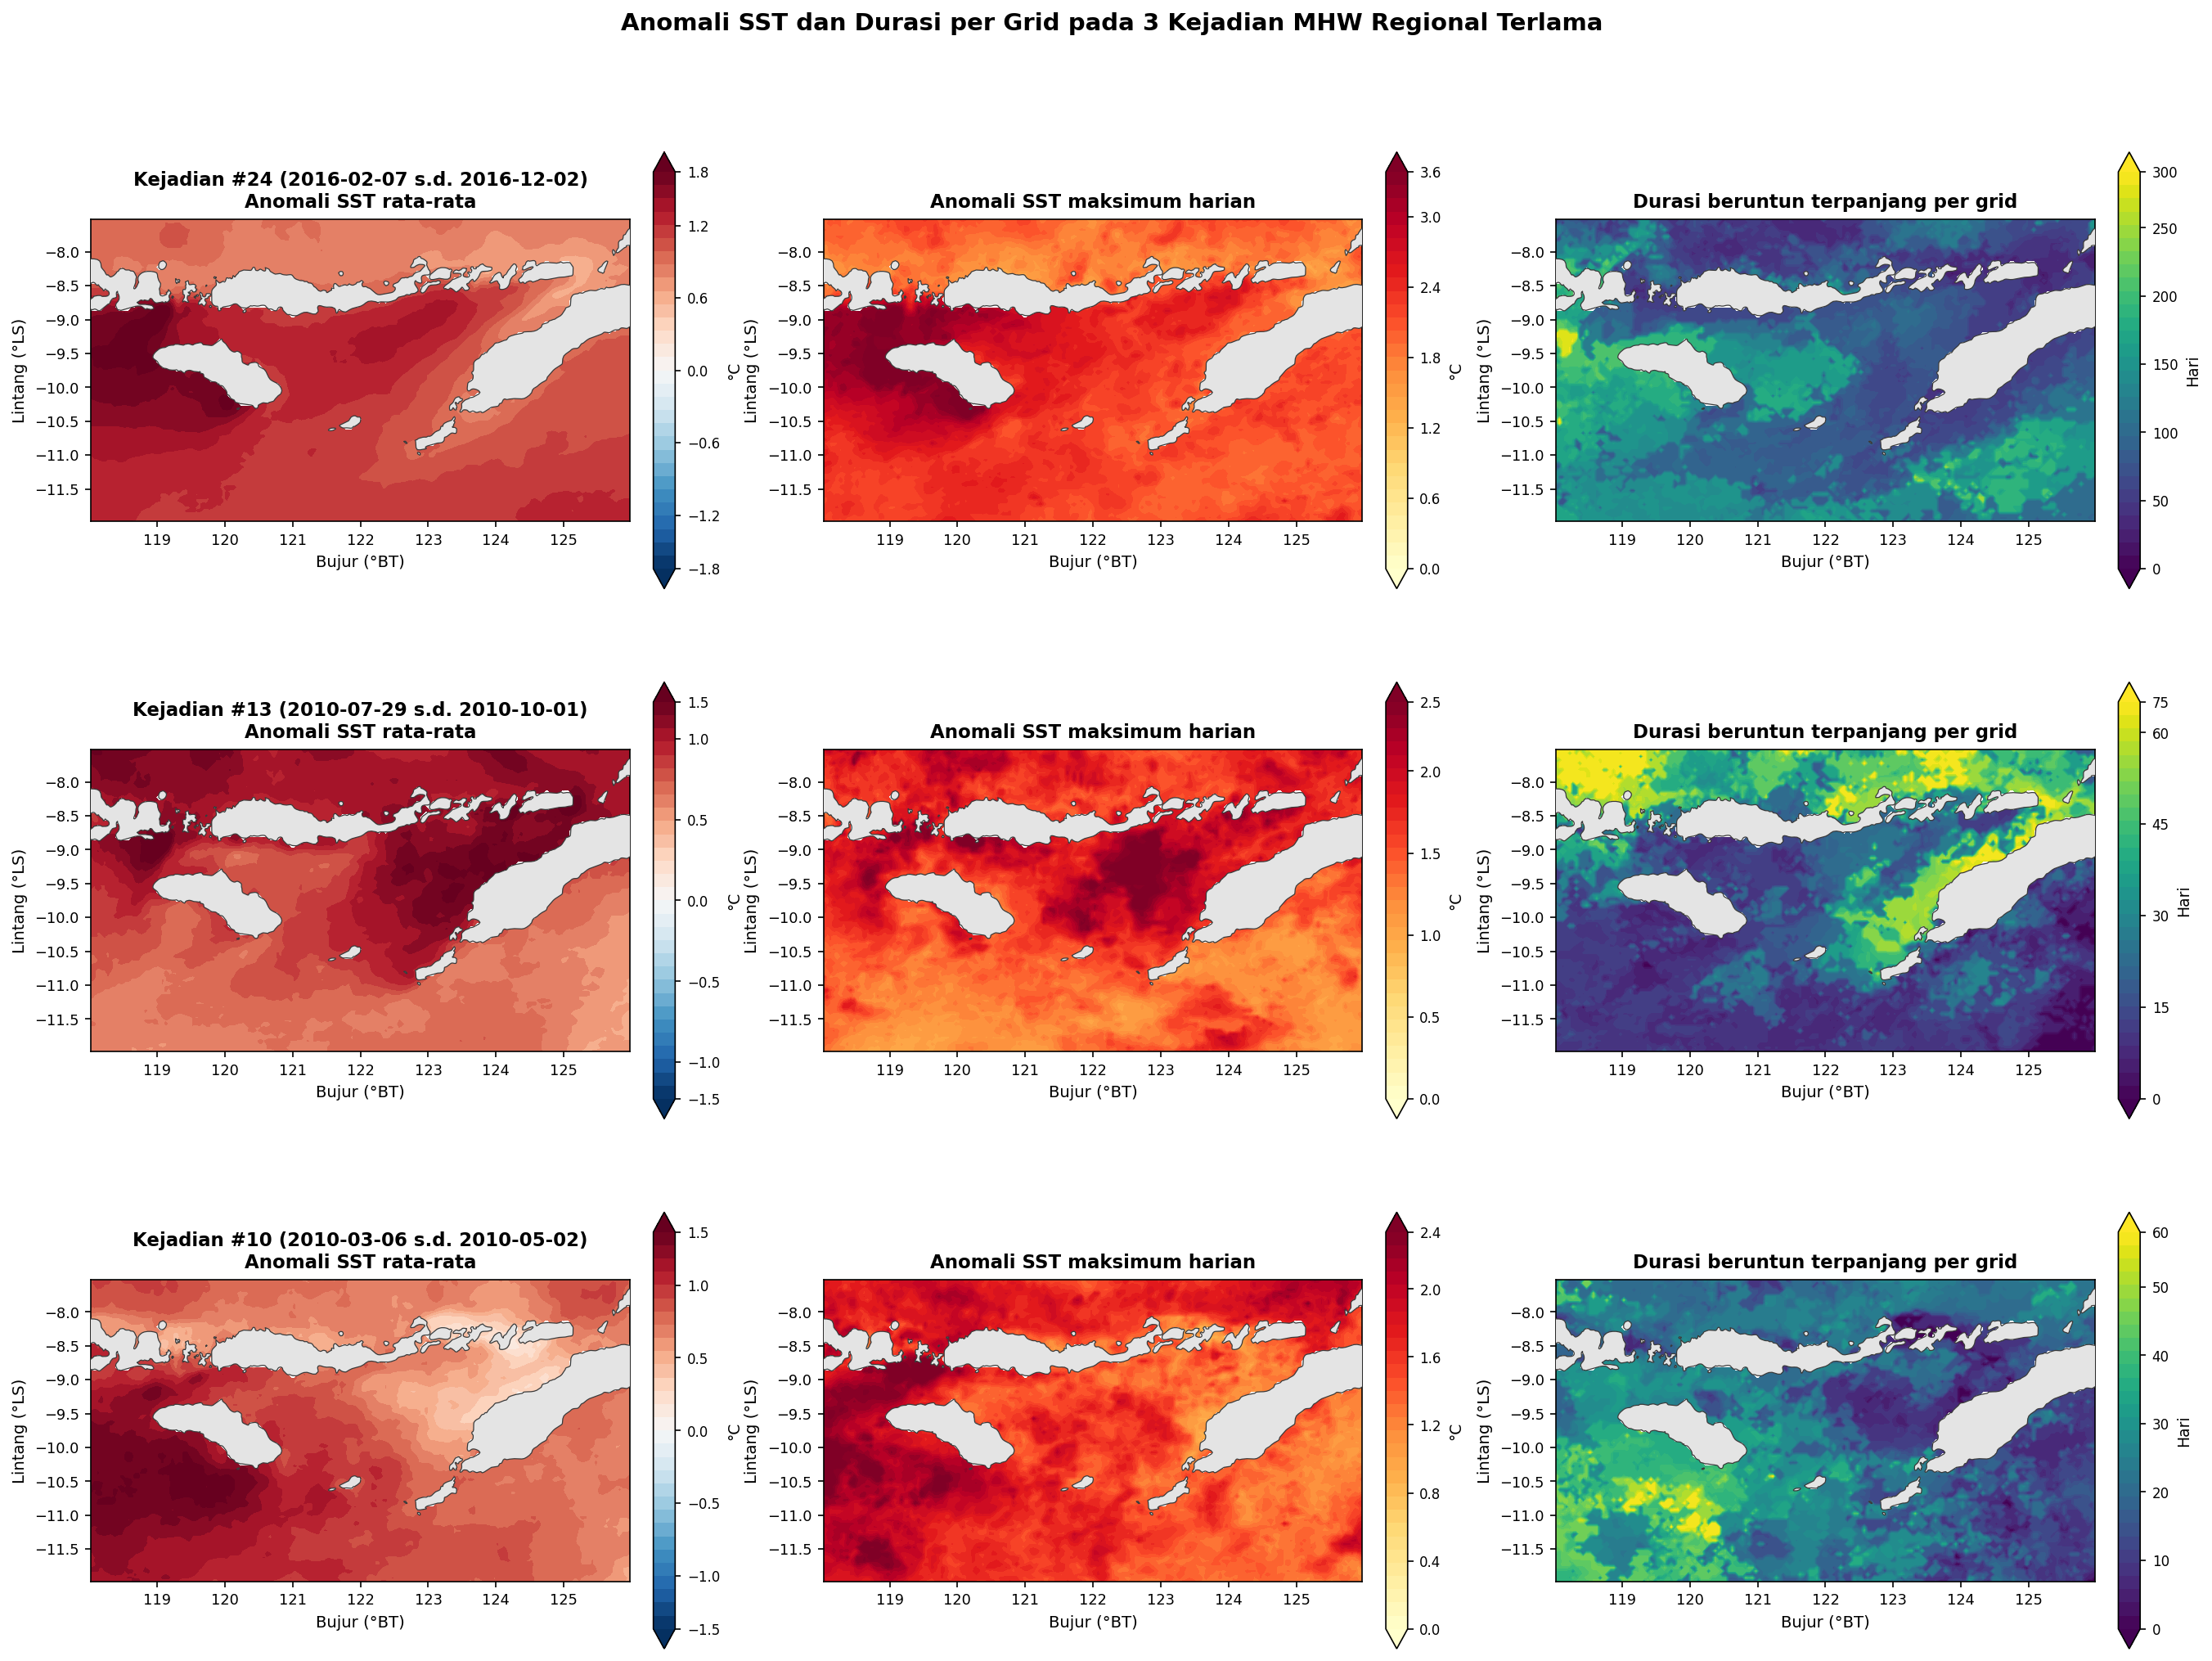

In [9]:
# Peta anomali SST (rata-rata dan maksimum harian) dan durasi beruntun per grid untuk 3 kejadian terlama
top3_ids = df_reg.sort_values('duration_days', ascending=False).head(3)['regional_event_id'].astype(int).tolist()
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for r, eid in enumerate(top3_ids):
    ev = df_reg[df_reg['regional_event_id'] == eid].iloc[0]
    d = ds_event_maps.sel(regional_event_id=eid)
    lim = max(float(np.nanpercentile(np.abs(d['anomaly_mean'].values), 98)), 0.5)
    plot_smooth_map(axes[r, 0], ds_sst.lon.values, ds_sst.lat.values, d['anomaly_mean'].values, var_type='continuous', cmap='RdBu_r', vmin=-lim, vmax=lim, levels=31,
                    title=f"Kejadian #{eid} ({ev['start_date']} s.d. {ev['end_date']})\nAnomali SST rata-rata", cbar_label='°C', gdf_land=gdf_land)
    limx = max(float(np.nanpercentile(d['anomaly_max'].values, 98)), 0.5)
    plot_smooth_map(axes[r, 1], ds_sst.lon.values, ds_sst.lat.values, d['anomaly_max'].values, var_type='continuous', cmap='YlOrRd', vmin=0, vmax=limx, levels=31,
                    title='Anomali SST maksimum harian', cbar_label='°C', gdf_land=gdf_land)
    dmax = max(float(np.nanmax(d['duration_run'].values)), 1.0)
    plot_smooth_map(axes[r, 2], ds_sst.lon.values, ds_sst.lat.values, d['duration_run'].values, var_type='continuous', cmap='viridis', vmin=0, vmax=dmax, levels=31,
                    title='Durasi beruntun terpanjang per grid', cbar_label='Hari', gdf_land=gdf_land)
plt.suptitle('Anomali SST dan Durasi per Grid pada 3 Kejadian MHW Regional Terlama', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig(cfg.FIGURES_DIR / "nb5_per_event_anomaly_maps.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()


In [10]:
# Ekstraksi statistik klorofil-a untuk tabel sintesis
if cfg.CHLA_STATS_OUTPUT.exists():
    df_chla_stats = pd.read_csv(cfg.CHLA_STATS_OUTPUT, index_col=0)
    if 'median_p50_mg_m3' in df_chla_stats.index:
        chla_median_str = f"{df_chla_stats.loc['median_p50_mg_m3', 'Nilai']:.3f} mg/m³"
    else:
        chla_median_str = "0.207 mg/m³"
else:
    chla_median_str = "0.207 mg/m³"

# REVISI: nilai dihitung dari data (bukan angka tetap)
_m = ds_chla['chlor_a'].mean(dim=['lat', 'lon'], skipna=True).groupby('time.month').mean()
_jja = _m.sel(month=[6, 7, 8]).values
_pg_pooled = cfg.TABLES_DIR / "chla_mhw_per_grid_pooled_ntt.csv"
if _pg_pooled.exists():
    _pg = pd.read_csv(_pg_pooled).iloc[0]
    _resp_nilai = f"Anomali {_pg['anomali_mhw_mean']:+.3f} mg/m³; {_pg['pct_sel_turun']:.0f}% sel turun ({_pg['pct_sel_turun_signifikan']:.0f}% signifikan, FDR q<0.05)"
    _resp_ket = f"Per grid: {int(_pg['sel_hari_mhw']):,} sel-hari MHW (di atas P90) vs {int(_pg['sel_hari_non_mhw']):,} sel-hari non-MHW; hari jeda dikeluarkan"
else:
    _resp_nilai, _resp_ket = 'Belum tersedia (jalankan Notebook 4 bagian 5.1)', ''

summary_records = [
    {
        'Komponen': 'Karakteristik SST',
        'Metrik': 'Rentang Rata-rata Regional',
        'Nilai': f"{float(ds_sst['sst'].mean(dim=['lat', 'lon']).min()):.2f} – {float(ds_sst['sst'].mean(dim=['lat', 'lon']).max()):.2f} °C",
        'Keterangan': 'Nilai harian minimum terjadi saat puncak upwelling JJA, maksimum pada musim peralihan'
    },
    {
        'Komponen': 'Karakteristik SST',
        'Metrik': 'Rata-rata Klimatologis',
        'Nilai': f"{float(ds_sst['sst'].mean()):.2f} °C",
        'Keterangan': 'Baseline 2000–2020 (21 tahun data Copernicus / ESA SST CCI v3.0 (resolusi 0.05°))'
    },
    {
        'Komponen': 'Deteksi MHW',
        'Metrik': 'Total Kejadian Regional (2000–2020)',
        'Nilai': f"{len(df_reg_events)} kejadian",
        'Keterangan': 'Kriteria Hobday et al. (2016): ambang cakupan spasial ≥ 15% luas perairan NTT, durasi ≥ 5 hari'
    },
    {
        'Komponen': 'Deteksi MHW',
        'Metrik': 'Total Hari MHW Regional',
        'Nilai': f"{int(df_annual_mhw['total_hari_mhw'].sum())} hari",
        'Keterangan': f"Mencakup ~{100*df_annual_mhw['total_hari_mhw'].sum()/(21*365.25):.1f}% dari rentang 21 tahun"
    },
    {
        'Komponen': 'Deteksi MHW',
        'Metrik': 'Durasi Rata-rata per Kejadian',
        'Nilai': f"{df_reg_events['duration_days'].mean():.1f} hari",
        'Keterangan': f"Durasi terpanjang: {df_reg_events['duration_days'].max()} hari"
    },
    {
        'Komponen': 'Deteksi MHW',
        'Metrik': 'Intensitas Maksimum Tertinggi (imax)',
        'Nilai': f"{df_reg_events['i_max_regional'].max() if 'i_max_regional' in df_reg_events.columns else df_events['i_max'].max():.2f} °C",
        'Keterangan': f"Kejadian regional #{int(df_reg_events.loc[df_reg_events['i_max_regional'].idxmax(), 'regional_event_id'])} ({df_reg_events.loc[df_reg_events['i_max_regional'].idxmax(), 'start_date']}); nilai maksimum sel selama kejadian"
    },
    {
        'Komponen': 'Chlorophyll-a',
        'Metrik': 'Median Konsentrasi Global',
        'Nilai': chla_median_str,
        'Keterangan': 'Distribusi log-normal; nilai rata-rata aritmatika: 0.25–0.35 mg/m³'
    },
    {
        'Komponen': 'Chlorophyll-a',
        'Metrik': 'Puncak Musiman Upwelling (JJA)',
        'Nilai': f"{_jja.min():.2f} – {_jja.max():.2f} mg/m³ (Regional)",
        'Keterangan': 'Mencapai > 1.5 mg/m³ di koridor Selat Sumba dan Laut Sawu'
    },
    {
        'Komponen': 'Respon Gabungan',
        'Metrik': 'Perbedaan Median Chl-a saat MHW',
        'Nilai': _resp_nilai,
        'Keterangan': _resp_ket
    }
]

_ev_an = pd.read_csv(cfg.TABLES_DIR / "mhw_event_anomaly_summary_ntt.csv")
_chk = pd.read_csv(cfg.TABLES_DIR / "mhw_catalog_check_ntt.csv")
summary_records += [
    {'Komponen': 'Deteksi MHW', 'Metrik': 'Hari MHW Regional vs Hari Jeda', 'Nilai': f"{int(_chk['hari_mhw_regional'].sum())} vs {int(_chk['hari_jeda'].sum())} hari",
     'Keterangan': 'Hari jeda (cakupan <15%) bagian kejadian tetapi bukan hari MHW'},
    {'Komponen': 'Anomali SST per Grid', 'Metrik': 'Anomali Rata-rata Sel MHW (rata-rata kejadian)', 'Nilai': f"{_ev_an['anomali_rata2_sel_mhw_C'].mean():+.2f} °C",
     'Keterangan': 'Rata-rata SST periode kejadian dikurangi rata-rata SST 21 tahun pada tanggal yang sama, tiap grid'},
]
df_sintesis = pd.DataFrame(summary_records)
print("TABEL SINTESIS TEMUAN UTAMA:")
print(df_sintesis.to_string(index=False))

# Simpan tabel sintesis
df_sintesis.to_csv(cfg.TABLES_DIR / "summary_sintesis_temuan.csv", index=False)
print(f"\n✅ Tabel sintesis temuan disimpan: {cfg.TABLES_DIR / 'summary_sintesis_temuan.csv'}")


TABEL SINTESIS TEMUAN UTAMA:
            Komponen                                         Metrik                                                             Nilai                                                                                           Keterangan
   Karakteristik SST                     Rentang Rata-rata Regional                                                  25.79 – 31.42 °C                Nilai harian minimum terjadi saat puncak upwelling JJA, maksimum pada musim peralihan
   Karakteristik SST                         Rata-rata Klimatologis                                                          28.72 °C                    Baseline 2000–2020 (21 tahun data Copernicus / ESA SST CCI v3.0 (resolusi 0.05°))
         Deteksi MHW            Total Kejadian Regional (2000–2020)                                                       33 kejadian       Kriteria Hobday et al. (2016): ambang cakupan spasial ≥ 15% luas perairan NTT, durasi ≥ 5 hari
         Deteksi MHW           

---
## 8. Naskah Caption dan Pembahasan Sintesis untuk Laporan

### Naskah Caption Figur Laporan:
1. **Figur 1: Karakteristik Termal dan Siklus Musiman SST di Perairan NTT (2000–2020)**  
   *Deskripsi:* (a) Deret waktu suhu permukaan laut harian dan rata-rata bulanan hasil observasi Copernicus / ESA SST CCI v3.0 (resolusi 0.05°). (b) Siklus musiman bimodal yang memperlihatkan penurunan SST drastis pada Juli–Agustus akibat *wind-driven upwelling* Monsun Tenggara, serta suhu tertinggi pada masa transisi monsun (November–Desember). (c) Pola spasial rata-rata tahunan yang memperlihatkan suhu lebih dingin di koridor perairan selatan (Laut Sawu dan Samudra Hindia) dibandingkan Laut Flores di utara.
2. **Figur 2: Dinamika Garis Waktu, Frekuensi, dan Keparahan Marine Heatwave (MHW)**  
   *Deskripsi:* (a) Anomali harian SST dengan arsiran kejadian MHW berdasarkan algoritma Hobday et al. (2016). (b–d) Tren metrik tahunan berupa frekuensi kejadian, total hari MHW, dan intensitas kumulatif tahunan. (e) Komposisi kejadian MHW yang didominasi Kategori I (Moderat) dan Kategori II (Kuat), dengan kemunculan sporadis Kategori III (Parah).
3. **Figur 3: Pola Spasial Multi-Parameter Perairan NTT**  
   *Deskripsi:* Distribusi spasial hari MHW kumulatif (a) dan intensitas maksimum (b) dibandingkan dengan sebaran konsentrasi klorofil-a tahunan (c) dan puncak upwelling (d). Wilayah Laut Sawu dan pesisir selatan Timor memperlihatkan kontras biogeokimia yang sangat kuat antara musim upwelling normal dan gangguan termal.
4. **Figur 4: Respon Komparatif Chlorophyll-a Terhadap Kejadian MHW**  
   *Deskripsi:* (a) Distribusi perbandingan nilai klorofil-a pada kondisi MHW versus non-MHW. (b) Median anomali klorofil-a terstratifikasi per musim, mengonfirmasi bahwa saat MHW terjadi pada musim upwelling (JJA), terjadi pelemahan atau penekanan lonjakan biomassa fitoplankton secara signifikan.